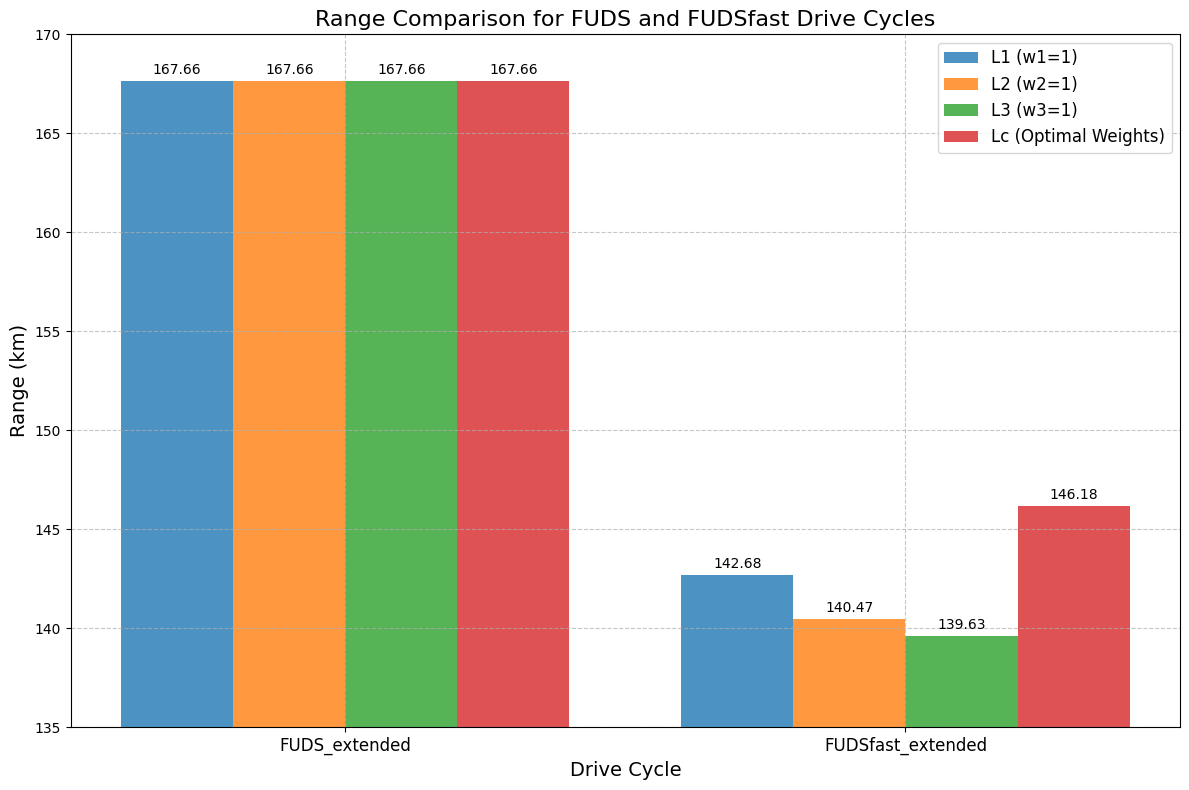

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create dataframe from the table data
data = {
    'w1': [1, 0, 0, 1, 0, 0, 0.95, 0.95],
    'w2': [0, 1, 0, 0, 1, 0, 0.97, 0.97],
    'w3': [0, 0, 1, 0, 0, 1, 0.81, 0.81],
    'wPL': [0.0000002, 0.0000002, 0.0000002, 0.0000002, 0.0000002, 0.0000002, 0.0000002, 0.0000002],
    'DC': ['FUDS_extended', 'FUDS_extended', 'FUDS_extended', 'FUDSfast_extended', 'FUDSfast_extended', 'FUDSfast_extended', 'FUDS_extended', 'FUDSfast_extended'],
    'predicted_range': [167.66, 167.66, 167.66, 142.68, 140.47, 139.63, 167.66, 146.18],
    'Range_from_Optimal_Weights': [167.66, 167.66, 167.66, 146.18, 146.18, 146.18, None, None]
}

df = pd.DataFrame(data)

# Fill NaN values in the Range_from_Optimal_Weights column for the last two rows
df.loc[6, 'Range_from_Optimal_Weights'] = 167.66
df.loc[7, 'Range_from_Optimal_Weights'] = 146.18

# Create separate dataframes for FUDS and FUDSfast
fuds_df = df[df['DC'] == 'FUDS_extended']
fudsfast_df = df[df['DC'] == 'FUDSfast_extended']

# Set up the plot
fig, ax = plt.subplots(figsize=(12, 8))

# Width of bars
bar_width = 0.2
opacity = 0.8

# Set positions for bars
index = np.arange(2)
categories = ['FUDS_extended', 'FUDSfast_extended']

# Extract the values for each category
# For w1=1, w2=0, w3=0
w1_ranges = [fuds_df[fuds_df['w1'] == 1]['predicted_range'].iloc[0],
             fudsfast_df[fudsfast_df['w1'] == 1]['predicted_range'].iloc[0]]

# For w1=0, w2=1, w3=0
w2_ranges = [fuds_df[fuds_df['w2'] == 1]['predicted_range'].iloc[0],
             fudsfast_df[fudsfast_df['w2'] == 1]['predicted_range'].iloc[0]]

# For w1=0, w2=0, w3=1
w3_ranges = [fuds_df[fuds_df['w3'] == 1]['predicted_range'].iloc[0],
             fudsfast_df[fudsfast_df['w3'] == 1]['predicted_range'].iloc[0]]

# For optimized weights (the last rows for each category)
opt_ranges = [fuds_df.iloc[-1]['Range_from_Optimal_Weights'],
              fudsfast_df.iloc[-1]['Range_from_Optimal_Weights']]

# Plot the bars
plt.bar(index - 1.5*bar_width, w1_ranges, bar_width, alpha=opacity, color='#1f77b4', label='L1 (w1=1)')
plt.bar(index - 0.5*bar_width, w2_ranges, bar_width, alpha=opacity, color='#ff7f0e', label='L2 (w2=1)')
plt.bar(index + 0.5*bar_width, w3_ranges, bar_width, alpha=opacity, color='#2ca02c', label='L3 (w3=1)')
plt.bar(index + 1.5*bar_width, opt_ranges, bar_width, alpha=opacity, color='#d62728', label='Lc (Optimal Weights)')

# Add labels, title and legend
plt.xlabel('Drive Cycle', fontsize=14)
plt.ylabel('Range (km)', fontsize=14)
plt.title('Range Comparison for FUDS and FUDSfast Drive Cycles', fontsize=16)
plt.xticks(index, categories, fontsize=12)
plt.legend(fontsize=12)


# Set y-axis limits
plt.ylim(135, 170)

# Add grid for better readability
plt.grid(True, linestyle='--', alpha=0.7)

# Add value labels on top of each bar
def add_labels(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=10)

add_labels(plt.bar(index - 1.5*bar_width, w1_ranges, bar_width, alpha=0))
add_labels(plt.bar(index - 0.5*bar_width, w2_ranges, bar_width, alpha=0))
add_labels(plt.bar(index + 0.5*bar_width, w3_ranges, bar_width, alpha=0))
add_labels(plt.bar(index + 1.5*bar_width, opt_ranges, bar_width, alpha=0))

plt.tight_layout()
plt.show()

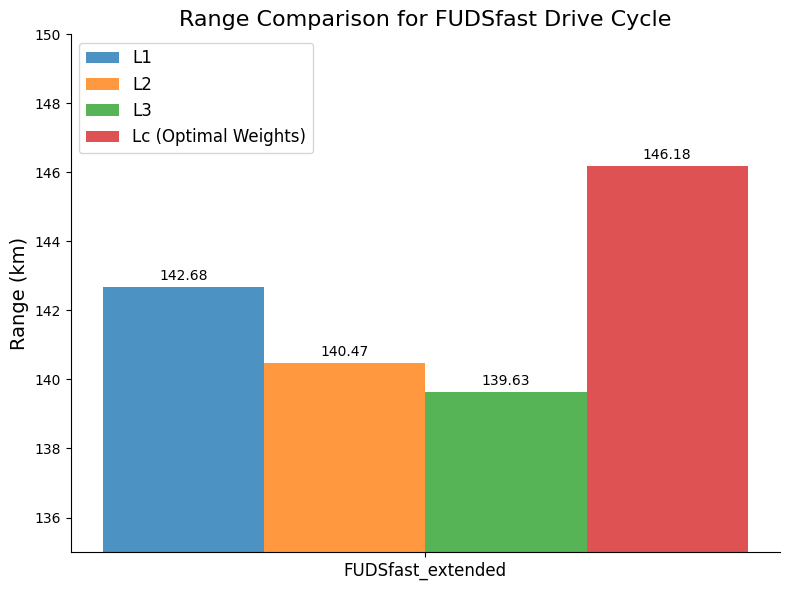

In [2]:
# Set up the plot
fig, ax = plt.subplots(figsize=(8, 6))

# Width of bars
bar_width = 0.2
opacity = 0.8

# Set positions for bars
index = np.array([0])  # Single position for FUDSfast
categories = ['FUDSfast_extended']

# Extract only the FUDSfast data
w1_range = fudsfast_df[fudsfast_df['w1'] == 1]['predicted_range'].iloc[0]
w2_range = fudsfast_df[fudsfast_df['w2'] == 1]['predicted_range'].iloc[0]
w3_range = fudsfast_df[fudsfast_df['w3'] == 1]['predicted_range'].iloc[0]
opt_range = fudsfast_df.iloc[-1]['Range_from_Optimal_Weights']

# Plot the bars
plt.bar(index - 1.5*bar_width, [w1_range], bar_width, alpha=opacity, color='#1f77b4', label='L1')
plt.bar(index - 0.5*bar_width, [w2_range], bar_width, alpha=opacity, color='#ff7f0e', label='L2')
plt.bar(index + 0.5*bar_width, [w3_range], bar_width, alpha=opacity, color='#2ca02c', label='L3')
plt.bar(index + 1.5*bar_width, [opt_range], bar_width, alpha=opacity, color='#d62728', label='Lc (Optimal Weights)')

# Add labels, title and legend
# plt.xlabel('Drive Cycle', fontsize=14)
plt.ylabel('Range (km)', fontsize=14)
plt.title('Range Comparison for FUDSfast Drive Cycle', fontsize=16)
plt.xticks(index, categories, fontsize=12)
plt.legend(fontsize=12)

# Set y-axis limits
plt.ylim(135, 150)

# Add grid for better readability
# plt.grid(True, linestyle='--', alpha=0.7)

# Add value labels on top of each bar
def add_labels(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=10)

add_labels(plt.bar(index - 1.5*bar_width, [w1_range], bar_width, alpha=0))
add_labels(plt.bar(index - 0.5*bar_width, [w2_range], bar_width, alpha=0))
add_labels(plt.bar(index + 0.5*bar_width, [w3_range], bar_width, alpha=0))
add_labels(plt.bar(index + 1.5*bar_width, [opt_range], bar_width, alpha=0))

# removing border lines from the top and right
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# # making the left and bottom border lines light grey
# plt.gca().spines['left'].set_color('lightgrey')
# plt.gca().spines['bottom'].set_color('lightgrey')


plt.tight_layout()
plt.show()


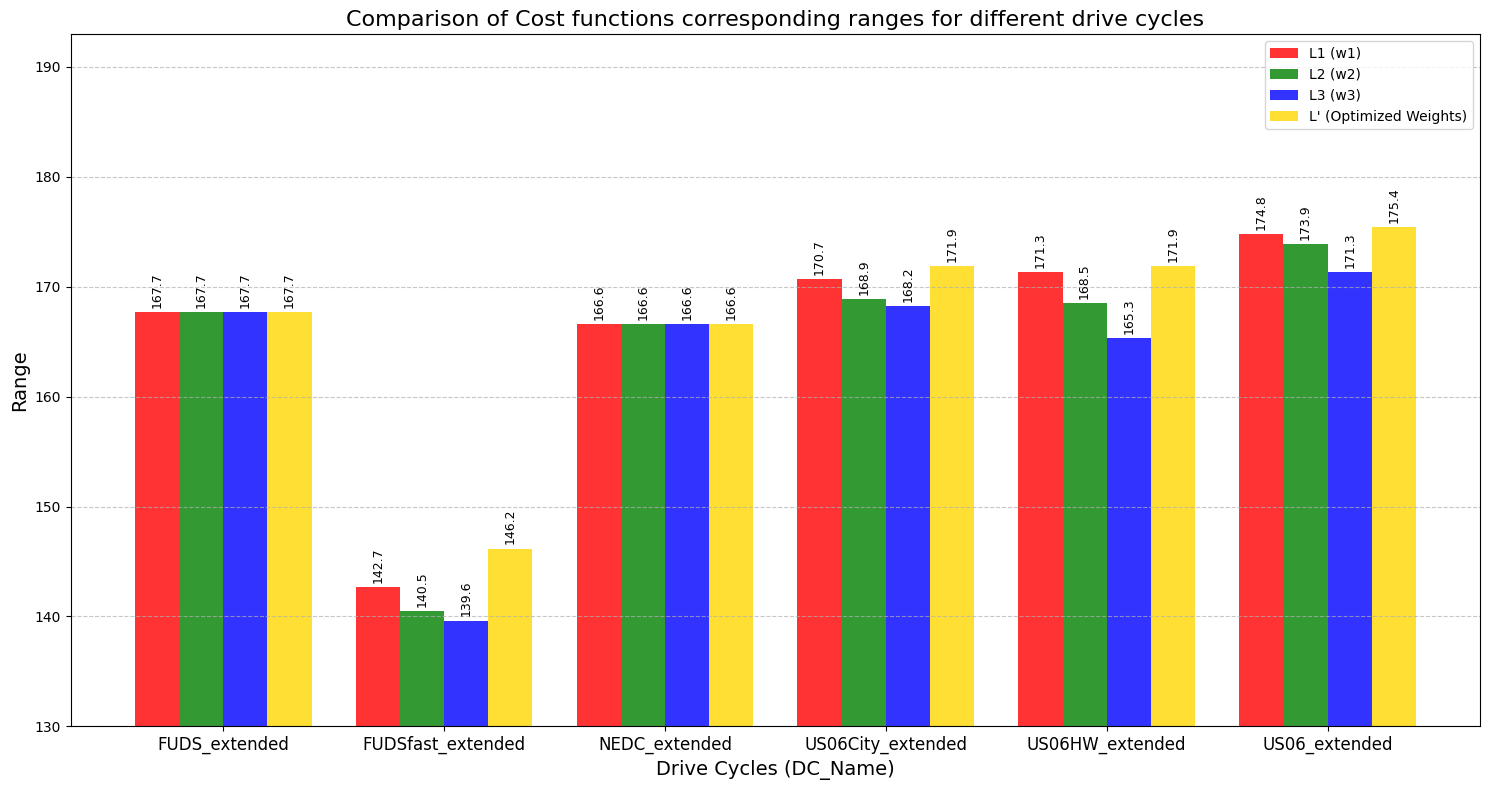

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create expanded dataframe from the table data, adding all drive cycles shown in your example
data = {
    'DC': ['FUDS_extended', 'FUDS_extended', 'FUDS_extended', 'FUDS_extended',
           'FUDSfast_extended', 'FUDSfast_extended', 'FUDSfast_extended', 'FUDSfast_extended',
           'NEDC_extended', 'NEDC_extended', 'NEDC_extended', 'NEDC_extended',
           'US06City_extended', 'US06City_extended', 'US06City_extended', 'US06City_extended',
           'US06HW_extended', 'US06HW_extended', 'US06HW_extended', 'US06HW_extended',
           'US06_extended', 'US06_extended', 'US06_extended', 'US06_extended'],
    'Weight_Type': ['L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)',
                   'L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)',
                   'L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)',
                   'L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)',
                   'L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)',
                   'L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)'],
    'Range': [
        # FUDS_extended values - using the data from your table
        167.66, 167.66, 167.66, 167.66,
        # FUDSfast_extended values - using the data from your table
        142.68, 140.47, 139.63, 146.18,
        # NEDC_extended values - based on your graph
        166.6, 166.6, 166.6, 166.6,
        # US06City_extended values - based on your graph
        170.7, 168.9, 168.2, 171.9,
        # US06HW_extended values - based on your graph
        171.3, 168.5, 165.3, 171.9,
        # US06_extended values - based on your graph
        174.8, 173.9, 171.3, 175.4
    ]
}

# Create DataFrame
df = pd.DataFrame(data)

# Set up the figure
fig, ax = plt.subplots(figsize=(15, 8))

# Define the colors for each weight type
colors = {'L1 (w1)': 'red', 'L2 (w2)': 'green', 'L3 (w3)': 'blue', 'L\' (Optimized Weights)': 'gold'}

# Width of bars
bar_width = 0.2
opacity = 0.8

# Set positions for bars
categories = df['DC'].unique()
x = np.arange(len(categories))

# Plot each group of bars
for i, weight_type in enumerate(['L1 (w1)', 'L2 (w2)', 'L3 (w3)', 'L\' (Optimized Weights)']):
    values = df[df['Weight_Type'] == weight_type]['Range'].values
    position = x + (i - 1.5) * bar_width
    rects = plt.bar(position, values, bar_width, alpha=opacity, color=colors[weight_type], label=weight_type)
    
    # Add value labels on top of each bar
    for j, rect in enumerate(rects):
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=9, rotation=90)

# Add labels, title and legend
plt.xlabel('Drive Cycles (DC_Name)', fontsize=14)
plt.ylabel('Range', fontsize=14)
plt.title('Comparison of Cost functions corresponding ranges for different drive cycles', fontsize=16)
plt.xticks(x, categories, fontsize=12)
plt.legend(loc='upper right', fontsize=10)



# Add grid for better readability
plt.grid(True, linestyle='--', alpha=0.7, axis='y')

# Set y-axis to start from 0
plt.ylim(bottom=130, top=max(df['Range']) * 1.1)

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

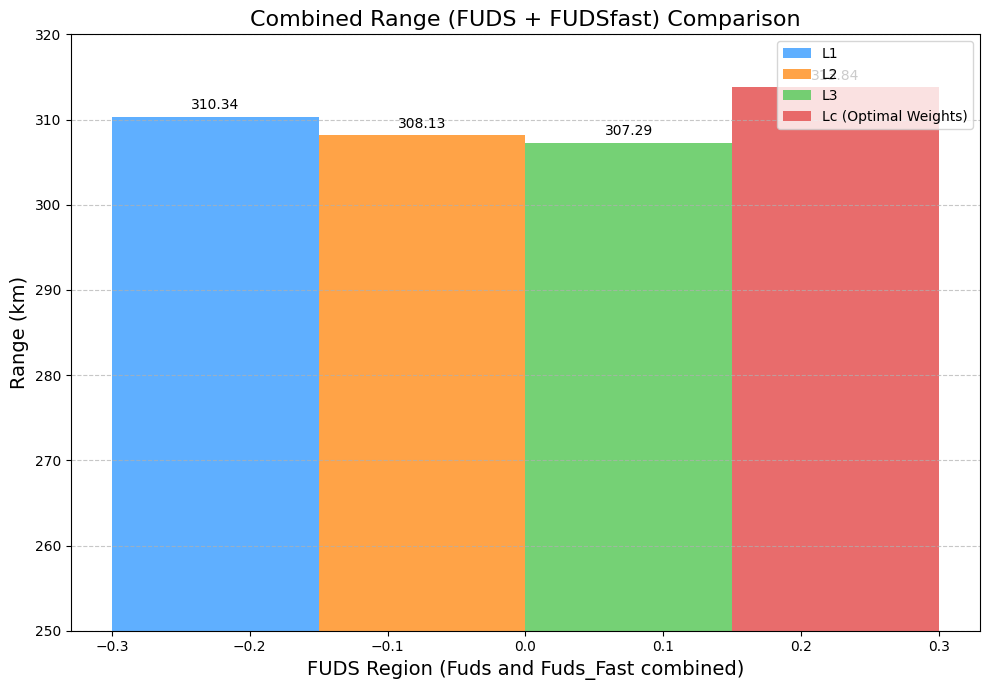

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Create data based on your table values
data = {
    'Weight_Type': ['L1', 'L2', 'L3', 'Lc (Optimal Weights)'],
    'FUDS_extended': [167.66, 167.66, 167.66, 167.66],
    'FUDSfast_extended': [142.68, 140.47, 139.63, 146.18]
}

# Create DataFrame
df = pd.DataFrame(data)

# Calculate the sum of ranges for each weight type
df['Combined_Range'] = df['FUDS_extended'] + df['FUDSfast_extended']

# Set up the figure
plt.figure(figsize=(10, 7))

# Define the colors matched to your example
colors = ['#4da6ff', '#ff9933', '#66cc66', '#e65c5c']  # Blue, Orange, Green, Red

# Width of bars
bar_width = 0.6
opacity = 0.9

# Set positions for bars
x = np.array([0])  # Single x position

# Plot each bar
for i, (weight_type, range_val) in enumerate(zip(df['Weight_Type'], df['Combined_Range'])):
    position = x + (i - 1.5) * (bar_width/4)  # Position bars closely together
    rect = plt.bar(position, range_val, bar_width/4, alpha=opacity, color=colors[i], label=weight_type)
    
    # Add value labels on top of each bar
    for bar in rect:
        height = bar.get_height()
        plt.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=10)

# Add labels, title and legend
plt.xlabel('FUDS Region (Fuds and Fuds_Fast combined)', fontsize=14)
plt.ylabel('Range (km)', fontsize=14)
plt.title('Combined Range (FUDS + FUDSfast) Comparison', fontsize=16)
plt.legend(fontsize=10, loc='upper right')

# Add grid for better readability
plt.grid(True, linestyle='--', alpha=0.7, axis='y')

# Set y-axis limits
plt.ylim(bottom=250, top=320)  # Adjusted based on the combined values

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()

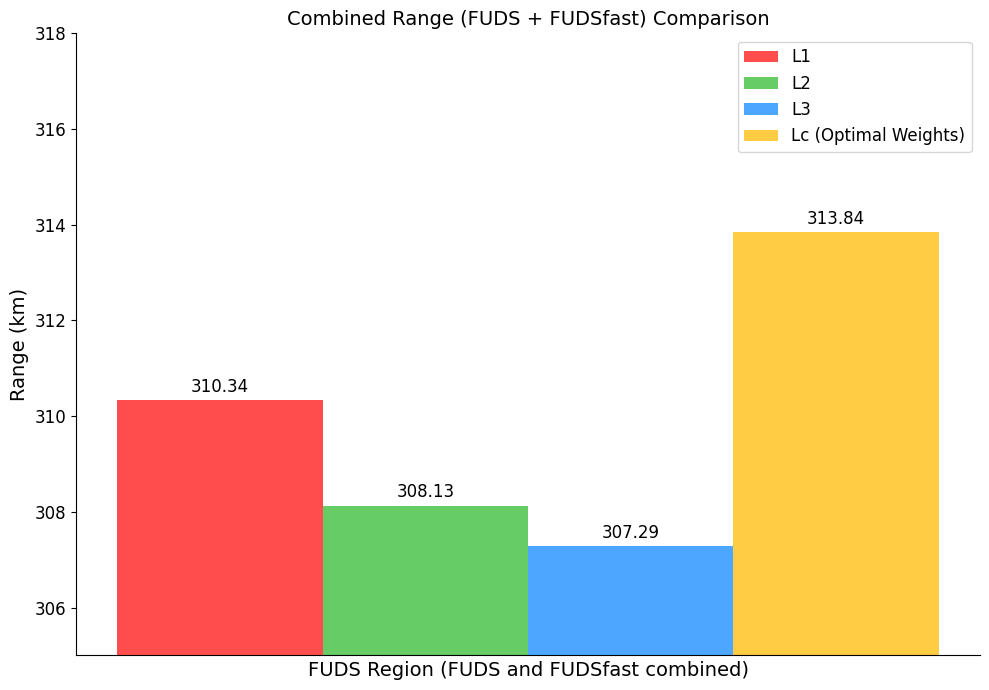

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Set up the figure
plt.figure(figsize=(10, 7), dpi=100)

# Define the colors matched exactly to your example
colors = ['#ff4d4d', '#66cc66', '#4da6ff', '#ffcc44']  # Red, Green, Blue, Yellow

# Width of bars - reducing the width as requested
bar_width = 0.15  # Reduced from 0.18
opacity = 1.0

# Set positions for bars
x = np.array([0])  # Single x position

# Plot each bar
for i, (weight_type, range_val) in enumerate(zip(df['Weight_Type'], df['Combined_Range'])):
    position = x + (i - 1.5) * bar_width  # Position bars with spacing
    rect = plt.bar(position, range_val, bar_width, alpha=opacity, color=colors[i], label=weight_type)
    
    # Add value labels on top of each bar
    for bar in rect:
        height = bar.get_height()
        plt.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=12)  # Increased from 10

# Add labels, title and legend
plt.xlabel('FUDS Region (FUDS and FUDSfast combined)', fontsize=14)
plt.ylabel('Range (km)', fontsize=14)
plt.title('Combined Range (FUDS + FUDSfast) Comparison', fontsize=14)

# Remove x-ticks since we're using a single category
plt.xticks([])

# Add legend matching the style in your reference image
legend_labels = ['L1', 'L2', 'L3', 'Lc (Optimal Weights)']
plt.legend(legend_labels, fontsize=12, loc='upper right')

# Add grid for better readability
plt.grid(True, linestyle='-', alpha=0.2, axis='both')

# Set y-axis limits to be from 300 to 320 as requested
plt.ylim(bottom=305, top=318)

# Increase the size of y-axis tick labels
plt.yticks(fontsize=12)  # Increased tick label size

# removing border lines from the top and right
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Set background color to white
ax = plt.gca()
ax.set_facecolor('white')

# Adjust layout
plt.tight_layout()

# remove grid lines
plt.grid(False)

# Show plot
plt.show()
